# Customer Churn Prediction and Retention Analytics

**Tools:** Python, Pandas, NumPy, Matplotlib, Scikit-learn

## Project Overview

Customer churn occurs when customers discontinue their relationship with a company, resulting in potential revenue loss.

This project analyses a telecommunications dataset containing 7,043 customer records to investigate factors associated with customer churn and develop machine learning models capable of estimating churn probabilities.

The project uses exploratory data analysis, feature engineering, Logistic Regression and Random Forest to analyse customer behaviour and evaluate predictive performance.

The selected model is then used to rank customers by churn risk and explore potential customer retention strategies.

## Project Objectives

1. Analyse customer characteristics and identify patterns associated with churn.
2. Prepare and clean customer data for machine learning.
3. Develop and compare classification models.
4. Evaluate model performance using appropriate statistical metrics.
5. Identify high risk customers using predicted churn probabilities.
6. Explore the potential financial benefits of targeted customer retention strategies.

In [48]:
import pandas as pd

In [49]:

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [50]:
print(df.shape)

print(df.columns.tolist())

df.info()

(7043, 21)
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   ob

In [51]:
df.isnull().sum()


,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [52]:
df["TotalCharges"].dtype

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

print(df["TotalCharges"].dtype)

print(df["TotalCharges"].isnull().sum())



float64
11


In [53]:

df[df["TotalCharges"].isnull()][
    ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]
]


,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,NaN,No
753,0,20.25,NaN,No
936,0,80.85,NaN,No
1082,0,25.75,NaN,No
1340,0,56.05,NaN,No
3331,0,19.85,NaN,No
3826,0,25.35,NaN,No
4380,0,20.00,NaN,No
5218,0,19.70,NaN,No
6670,0,73.35,NaN,No


In [54]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


In [55]:
df["Churn"].value_counts(normalize=True) * 100


,proportion
Churn,
No,73.463013
Yes,26.536987


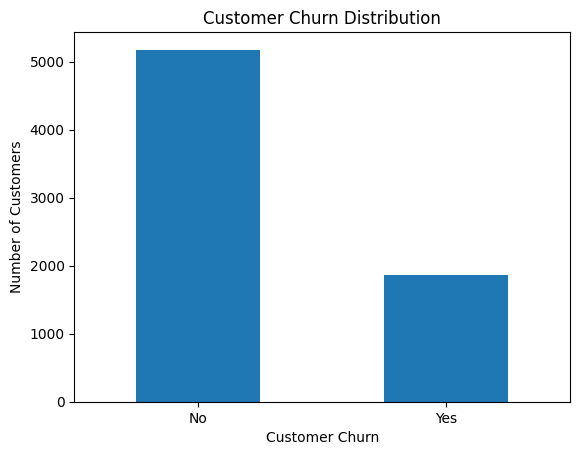

In [56]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

churn_counts.plot(kind="bar")

plt.title("Customer Churn Distribution")
plt.xlabel("Customer Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.show()



In [57]:
df["ChurnFlag"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

contract_churn = (
    df.groupby("Contract")["ChurnFlag"]
    .mean() * 100
)

print(contract_churn.round(2))


Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: ChurnFlag, dtype: float64


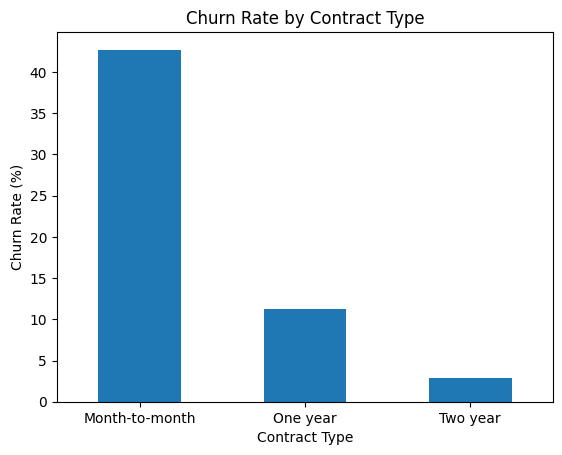

In [58]:
contract_churn.plot(kind="bar")

plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()


In [59]:
df.groupby("Churn")["MonthlyCharges"].mean()


,MonthlyCharges
Churn,
No,61.265124
Yes,74.441332


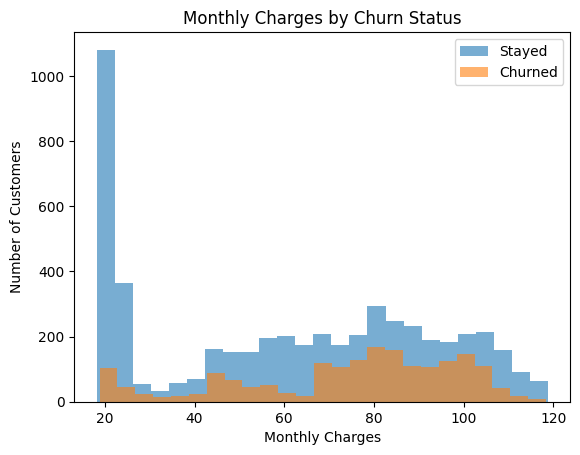

In [60]:
plt.hist(
    df[df["Churn"] == "No"]["MonthlyCharges"],
    bins=25,
    alpha=0.6,
    label="Stayed"
)

plt.hist(
    df[df["Churn"] == "Yes"]["MonthlyCharges"],
    bins=25,
    alpha=0.6,
    label="Churned"
)

plt.title("Monthly Charges by Churn Status")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.legend()

plt.show()


In [61]:
df.groupby("Churn")["tenure"].mean()


,tenure
Churn,
No,37.569965
Yes,17.979133


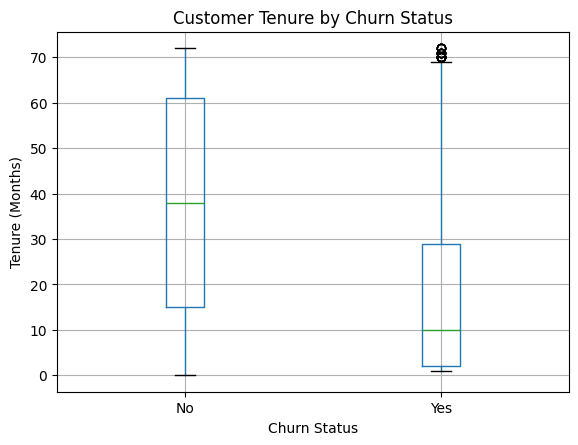

In [62]:
df.boxplot(column="tenure", by="Churn")

plt.title("Customer Tenure by Churn Status")
plt.suptitle("")
plt.xlabel("Churn Status")
plt.ylabel("Tenure (Months)")

plt.show()


In [63]:
print(
    df.groupby("InternetService")["ChurnFlag"]
    .mean() * 100
)

print(
    df.groupby("PaymentMethod")["ChurnFlag"]
    .mean() * 100
)

print(
    df.groupby("TechSupport")["ChurnFlag"]
    .mean() * 100
)


InternetService
DSL            18.959108
Fiber optic    41.892765
No              7.404980
Name: ChurnFlag, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.709845
Credit card (automatic)      15.243101
Electronic check             45.285412
Mailed check                 19.106700
Name: ChurnFlag, dtype: float64
TechSupport
No                     41.635474
No internet service     7.404980
Yes                    15.166341
Name: ChurnFlag, dtype: float64


In [64]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

missing_new_customers = (
    (df["tenure"] == 0) &
    (df["TotalCharges"].isna())
)

df.loc[missing_new_customers, "TotalCharges"] = 0

print(df.isnull().sum().sum())

print(df["TotalCharges"].dtype)


0
float64


In [65]:
y = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

X = df.drop(
    columns=["customerID", "Churn", "ChurnFlag"],
    errors="ignore"
)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7043, 19)
y shape: (7043,)


In [66]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (5634, 19)
Testing data: (1409, 19)


In [67]:
numeric_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [68]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created.")


Preprocessing pipeline created.


In [69]:

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        random_state=42,
        n_jobs=-1
    ))
])

print("Both models created successfully!")


Both models created successfully!


In [70]:
logistic_model.fit(X_train, y_train)

forest_model.fit(X_train, y_train)

print("Both models trained successfully!")


Both models trained successfully!


In [71]:
logistic_predictions = logistic_model.predict(X_test)

forest_predictions = forest_model.predict(X_test)

print("Logistic Regression:")
print(logistic_predictions[:10])

print("Random Forest:")
print(forest_predictions[:10])


Logistic Regression:
[0 1 0 0 0 1 0 0 0 0]
Random Forest:
[0 1 0 0 0 0 0 0 0 0]


In [72]:
from sklearn.metrics import accuracy_score

logistic_accuracy = accuracy_score(
    y_test,
    logistic_predictions
)

forest_accuracy = accuracy_score(
    y_test,
    forest_predictions
)

print("Logistic Regression Accuracy:",
      round(logistic_accuracy * 100, 2), "%")

print("Random Forest Accuracy:",
      round(forest_accuracy * 100, 2), "%")


Logistic Regression Accuracy: 80.55 %
Random Forest Accuracy: 79.49 %


In [73]:
logistic_probabilities = logistic_model.predict_proba(
    X_test
)[:, 1]

forest_probabilities = forest_model.predict_proba(
    X_test
)[:, 1]

print("Logistic Regression probabilities:")
print(logistic_probabilities[:10])

print("\nRandom Forest probabilities:")
print(forest_probabilities[:10])


Logistic Regression probabilities:
[0.04591993 0.68371345 0.05893985 0.40183529 0.02142426 0.60297803
 0.44762898 0.13033554 0.00280355 0.39473874]

Random Forest probabilities:
[0.00529349 0.71023318 0.0582616  0.29035286 0.02612103 0.49761727
 0.3389303  0.09200063 0.00103184 0.42498903]


In [74]:
comparison = pd.DataFrame({
    "Actual Churn": y_test.to_numpy()[:5],
    "Logistic Probability": logistic_probabilities[:5],
    "Random Forest Probability": forest_probabilities[:5]
})

print(comparison.round(3))


   Actual Churn  Logistic Probability  Random Forest Probability
0             0                 0.046                      0.005
1             0                 0.684                      0.710
2             0                 0.059                      0.058
3             0                 0.402                      0.290
4             0                 0.021                      0.026


In [75]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

models = {
    "Logistic Regression": (
        logistic_predictions,
        logistic_probabilities
    ),
    "Random Forest": (
        forest_predictions,
        forest_probabilities
    )
}

results = []

for name, (predictions, probabilities) in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1 Score": f1_score(y_test, predictions),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))


                 Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC
0  Logistic Regression     0.806      0.657   0.559     0.604    0.842
1        Random Forest     0.795      0.647   0.500     0.564    0.837


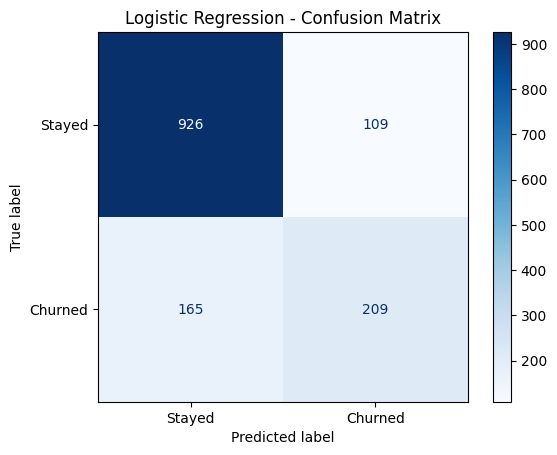

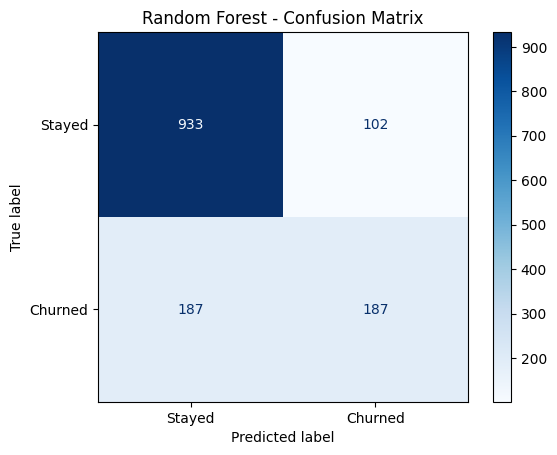

In [76]:

from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Logistic Regression
ConfusionMatrixDisplay.from_predictions(
    y_test,
    logistic_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

# Random Forest
ConfusionMatrixDisplay.from_predictions(
    y_test,
    forest_predictions,
    display_labels=["Stayed", "Churned"],
    cmap="Blues"
)

plt.title("Random Forest - Confusion Matrix")
plt.show()


In [77]:

from sklearn.model_selection import cross_validate

model_pipelines = {
    "Logistic Regression": logistic_model,
    "Random Forest": forest_model
}

cv_results = []

for name, model in model_pipelines.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=5,
        scoring={
            "roc_auc": "roc_auc",
            "recall": "recall",
            "precision": "precision"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV ROC-AUC": scores["test_roc_auc"].mean(),
        "CV Recall": scores["test_recall"].mean(),
        "CV Precision": scores["test_precision"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df.round(3))


                 Model  CV ROC-AUC  CV Recall  CV Precision
0  Logistic Regression       0.846      0.548         0.658
1        Random Forest       0.842      0.499         0.662


In [78]:
best_name = cv_results_df.loc[
    cv_results_df["CV ROC-AUC"].idxmax(),
    "Model"
]

best_model = model_pipelines[best_name]

print("Selected model:", best_name)


Selected model: Logistic Regression


In [79]:
customer_risks = X_test.copy()

customer_risks["customerID"] = df.loc[
    X_test.index, "customerID"
]

customer_risks["Actual_Churn"] = y_test

customer_risks["Churn_Probability"] = (
    best_model.predict_proba(X_test)[:, 1]
)

customer_risks = customer_risks.sort_values(
    "Churn_Probability",
    ascending=False
)

customer_risks[[
    "customerID",
    "tenure",
    "Contract",
    "MonthlyCharges",
    "Churn_Probability",
    "Actual_Churn"
]].head(10).round(3)


,customerID,tenure,Contract,MonthlyCharges,Churn_Probability,Actual_Churn
3380,5178-LMXOP,1,Month-to-month,95.10,0.854,1
6866,0295-PPHDO,1,Month-to-month,95.45,0.832,1
2631,6861-XWTWQ,7,Month-to-month,99.25,0.828,1
6365,8884-ADFVN,7,Month-to-month,101.95,0.822,1
4585,1069-XAIEM,1,Month-to-month,85.05,0.818,1
2797,6023-YEBUP,3,Month-to-month,100.95,0.818,1
3346,2545-EBUPK,2,Month-to-month,84.05,0.817,0
3727,9057-SIHCH,3,Month-to-month,96.60,0.817,1
6894,1400-MMYXY,3,Month-to-month,105.90,0.816,1
935,6630-UJZMY,4,Month-to-month,83.25,0.812,0


In [80]:
customer_risks["Risk_Category"] = pd.cut(
    customer_risks["Churn_Probability"],
    bins=[0, 0.3, 0.6, 1.0],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

print(customer_risks["Risk_Category"].value_counts())


Risk_Category
Low       866
Medium    334
High      209
Name: count, dtype: int64


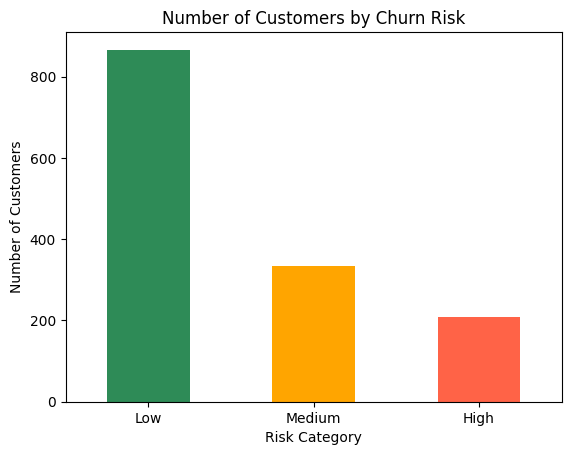

In [81]:
risk_counts = customer_risks["Risk_Category"].value_counts()

risk_counts.plot(
    kind="bar",
    color=["seagreen", "orange", "tomato"]
)

plt.title("Number of Customers by Churn Risk")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()


In [82]:
risk_summary = customer_risks.groupby(
    "Risk_Category",
    observed=True
).agg(
    Customers=("Actual_Churn", "count"),
    Actual_Churn_Rate=("Actual_Churn", "mean"),
    Average_Predicted_Risk=("Churn_Probability", "mean")
)

risk_summary["Actual_Churn_Rate"] *= 100
risk_summary["Average_Predicted_Risk"] *= 100

print(risk_summary.round(2))


               Customers  Actual_Churn_Rate  Average_Predicted_Risk
Risk_Category                                                      
Low                  866              10.62                    9.44
Medium               334              39.52                   45.06
High                 209              71.77                   69.40


In [83]:
from sklearn.inspection import permutation_importance

importance = permutation_importance(
    best_model,
    X_test,
    y_test,
    scoring="roc_auc",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.Series(
    importance.importances_mean,
    index=X_test.columns
)

feature_importance = feature_importance.sort_values(
    ascending=False
)

print(feature_importance.round(4))


tenure              0.1724
InternetService     0.0387
Contract            0.0328
MonthlyCharges      0.0304
TotalCharges        0.0143
OnlineSecurity      0.0041
TechSupport         0.0039
StreamingMovies     0.0038
StreamingTV         0.0032
PaymentMethod       0.0032
MultipleLines       0.0030
OnlineBackup        0.0018
PaperlessBilling    0.0016
DeviceProtection    0.0013
SeniorCitizen       0.0011
Dependents          0.0008
PhoneService        0.0001
Partner            -0.0000
gender             -0.0001
dtype: float64


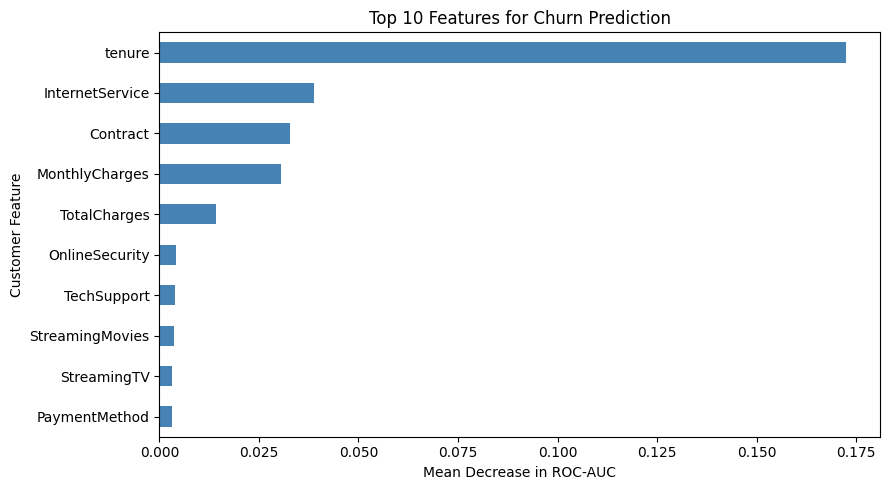

In [84]:
feature_importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Top 10 Features for Churn Prediction")
plt.xlabel("Mean Decrease in ROC-AUC")
plt.ylabel("Customer Feature")
plt.tight_layout()
plt.show()


In [85]:
top_100 = customer_risks.head(100).copy()

actual_churners = top_100["Actual_Churn"].sum()

top_100_churn_rate = actual_churners / 100 * 100

overall_churn_rate = y_test.mean() * 100

print("Customers selected:", len(top_100))
print("Actual churners in top 100:", actual_churners)

print("Churn rate in top 100:",
      round(top_100_churn_rate, 2), "%")

print("Overall test churn rate:",
      round(overall_churn_rate, 2), "%")


Customers selected: 100
Actual churners in top 100: 74
Churn rate in top 100: 74.0 %
Overall test churn rate: 26.54 %


In [86]:
lift = top_100_churn_rate / overall_churn_rate

print("Top 100 Lift:", round(lift, 2))


Top 100 Lift: 2.79


In [87]:
customers_contacted = len(top_100)

offer_cost = 20
retention_success_rate = 0.20
customer_value = 300

actual_churners = top_100["Actual_Churn"].sum()

expected_customers_saved = (
    actual_churners * retention_success_rate
)

campaign_cost = customers_contacted * offer_cost

estimated_value = (
    expected_customers_saved * customer_value
)

net_benefit = estimated_value - campaign_cost

print("Campaign cost: £", round(campaign_cost, 2))
print("Estimated customers retained:",
      round(expected_customers_saved, 1))
print("Estimated retention value: £",
      round(estimated_value, 2))
print("Estimated net benefit: £",
      round(net_benefit, 2))


Campaign cost: £ 2000
Estimated customers retained: 14.8
Estimated retention value: £ 4440.0
Estimated net benefit: £ 2440.0


In [88]:
customer_risks.to_csv(
    "customer_churn_risk_predictions.csv",
    index=False
)

cv_results_df.to_csv(
    "model_comparison.csv",
    index=False
)

feature_importance.to_csv(
    "feature_importance.csv",
    header=["Importance"]
)

print("Analysis files saved successfully!")


Analysis files saved successfully!


In [89]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

y_pred = best_model.predict(X_test)
y_prob = best_model.predict_proba(X_test)[:, 1]

final_metrics = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred),
        recall_score(y_test, y_pred),
        f1_score(y_test, y_pred),
        roc_auc_score(y_test, y_prob)
    ]
})

print(final_metrics.round(3))


      Metric  Score
0   Accuracy  0.806
1  Precision  0.657
2     Recall  0.559
3   F1 Score  0.604
4    ROC-AUC  0.842


In [90]:
import joblib

joblib.dump(
    best_model,
    "customer_churn_model.pkl"
)

print("Model saved successfully!")


Model saved successfully!


## Business Findings and Recommendations

### 1. Project Objective

The objective of this project was to analyse historical telecommunications customer data and develop a machine learning model to predict customer churn. Using a dataset of 7,043 customers, the project aimed to identify important factors associated with churn, compare predictive models and explore how churn predictions could support customer retention strategies.

### 2. Model Selection and Performance

Two machine learning models were developed and evaluated: Logistic Regression and Random Forest.

Using five fold cross validation, Logistic Regression achieved a mean ROC-AUC score of **0.846**, compared with **0.842** for Random Forest.

Logistic Regression also achieved a higher recall of **54.8%**, compared with **49.9%** for Random Forest, meaning it identified a greater proportion of customers who actually churned at the default classification threshold.

Although both models performed similarly, Logistic Regression was selected due to its slightly higher ROC-AUC, better recall and relative interpretability.

### 3. Customer Churn Patterns

Exploratory Data Analysis (EDA) identified several customer characteristics associated with higher churn rates.

- **Internet Service:** Customers with fibre optic internet had a churn rate of 41.89%, compared with 18.96% for DSL customers.
- **Payment Method:** Customers paying by electronic check had a churn rate of 45.29%, compared with 15.24% for customers paying by automatic credit card.
- **Technical Support:** Customers without technical support had a churn rate of 41.64%, compared with 15.17% for customers receiving technical support.

Feature importance analysis identified **customer tenure as the strongest predictor**, followed by internet service, contract type, monthly charges and total charges.

These findings suggest that customer tenure, service arrangements and billing characteristics are useful indicators of churn risk. However, these relationships are associations and do not establish causation.

### 4. Customer Risk Analysis

The selected Logistic Regression model was used to generate churn probability estimates for customers in the test dataset.

Customers were ranked according to their predicted probability of leaving the company.

**Key findings:**

- Customers selected for high-risk analysis: **100**
- Actual churners among the top 100: **74**
- Churn rate among the top 100: **74%**
- Overall test-set churn rate: **26.54%**
- Top 100 lift: **2.79×**

The analysis demonstrated that the model could concentrate customers who churned into a much smaller, higher risk group.

The top 100 customers had an observed churn rate approximately **2.79 times higher than the overall test population**.

This suggests that predictive modelling could help businesses prioritise customers for retention activities when resources are limited.

### 5. Business Recommendations

Based on the analysis, the following recommendations could be considered:

**1. Prioritise high-risk customers**

Use predicted churn probabilities to identify customers who may benefit from additional customer support or targeted retention offers. Customers could be prioritised according to their risk scores and potential business value.

**2. Investigate customer tenure**

Tenure was the most important feature in the predictive model. Further investigation into the relationship between customer tenure and churn could help identify stages of the customer lifecycle where additional support may be useful.

**3. Review technical support and service experience**

Customers without technical support showed substantially higher observed churn rates. The company could investigate whether access to technical assistance, service reliability or customer experience contributes to dissatisfaction.

**4. Evaluate targeted retention campaigns**

The company could test personalised retention offers among high risk customers. Controlled experiments would help determine whether these interventions actually reduce churn and provide positive financial returns.

### 6. Financial Impact Simulation

A hypothetical retention campaign was developed to estimate the potential financial value of targeting the 100 highest risk customers.

The following assumptions were used:

- Cost of contacting and offering retention incentives: £20 per customer

- Assumed retention success rate among customers who would otherwise churn: 20%

- Assumed value of retaining one customer: £300

Using the 74 observed churners among the top 100 customers, the scenario produced:


Campaign cost : £2,000

Expected customers retained : 14.8

Estimated retention value : £4,440

Estimated net benefit : £2,440

Under these assumptions, the campaign generated a positive estimated net benefit of £2,440.

These results are illustrative rather than realised financial outcomes. Actual profitability would depend on customer behaviour, intervention effectiveness, campaign costs and customer lifetime value.

###7. Limitations and Future Improvements

Several limitations should be considered:

The dataset is a fictional telecommunications sample and may not fully represent real world customer behaviour.

The model identifies predictive relationships rather than establishing causal factors behind churn.

The financial simulation relies on assumed retention success rates and customer values.

Model performance should be validated on new customer data before real world implementation.

The test dataset was inspected during development, limiting its status as a completely untouched final evaluation.

Future improvements could include probability calibration, classification threshold optimisation, more extensive hyperparameter tuning and testing retention campaigns through controlled experiments.

###8. Conclusion

This project demonstrated how Python, exploratory data analysis and machine learning can be combined to support customer retention decisions.

Logistic Regression achieved a mean cross validation ROC-AUC of 0.846 and successfully ranked customers by estimated churn risk. Among the 100 highest risk customers in the test dataset, 74 had actually churned, resulting in a lift of 2.79× compared with the overall churn rate.

The findings highlight the potential value of predictive analytics for identifying higher risk customers, prioritising retention efforts and supporting data driven business decisions.